> **Portfolio summary:** How an investigation into €500m of alleged money laundering changed Wise plc's downside risk, using 4 VaR / CVaR models, GARCH, Kupiec backtesting and an event study.
>
> [Project README](README.md) · [Back to the portfolio](../README.md)

# VaR and CVaR Analysis — Wise plc (WISE.L)
### MSc Financial Technology · Warwick Business School

This notebook estimates **Value-at-Risk (VaR)** and **Conditional Value-at-Risk (CVaR / Expected Shortfall)** for Wise plc, a UK-listed fintech firm, following its Belgian prosecution announcement.

**Structure**
- **Part A — Wise plc**: EDA · Nonparametric · Parametric (Normal + Student-t) · Bootstrap CIs · Kupiec Backtesting · GARCH · Event Study
- **Part B — Sector Comparison**: Wise idiosyncratic risk vs equal-weighted peer benchmark

**Peer selection rationale**: PayPal (PYPL), Block/Square (SQ), Adyen (ADYEN.AS) and Remitly (RELY) are selected on *business model similarity* — all operate in cross-border digital payments — ensuring comparable regulatory risk profiles. ARKF (an ETF) was excluded as its return distribution reflects portfolio diversification, not operational risk.

**Alpha levels reported**: α = 5% (primary, statistically reliable given ~850 observations), α = 2.5% (current Basel III / FRTB standard for CVaR), α = 1% (original Basel II standard, reported with caveat on precision).

## Setup

In [1]:
import sys, subprocess
subprocess.check_call(
    [sys.executable, '-m', 'pip', 'install', '--quiet',
     'numpy', 'scipy', 'matplotlib', 'pandas', 'yfinance', 'arch', 'seaborn', 'statsmodels'],
    stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from scipy.stats import norm, t as t_dist
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

import yfinance as yf
from arch import arch_model

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams.update({
    'figure.dpi': 110,
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'legend.fontsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# ── Global configuration ────────────────────────────────────────────────────────
WISE_TICKER  = 'WISE.L'
PEER_TICKERS = ['PYPL', 'SQ', 'ADYEN.AS', 'RELY']
START_DATE   = '2021-07-07'    # Wise IPO date
END_DATE     = '2024-12-31'
EVENT_DATE   = '2024-09-11'    # Belgian prosecution announcement — verify against FT article
ALPHAS       = [0.05, 0.025, 0.01]
ALPHA_MAIN   = 0.05
ROLLING_WIN  = 250
EVENT_WIN    = 10

# Colour palette — consistent throughout
C = dict(hist='steelblue', normal='tomato', tdist='seagreen',
         garch='crimson', garch_es='darkred', static='darkorange',
         event='black', wise='steelblue', sector='darkorange', tail='crimson')

print('Setup complete.')

Setup complete.

---
# Part A — Wise plc Risk Analysis
---

## 1. Data Collection and Return Computation

In [2]:
print('Downloading Wise plc (WISE.L)...')
raw         = yf.download(WISE_TICKER, start=START_DATE, end=END_DATE, progress=False)
wise_prices = raw['Close'].squeeze()
wise_ret    = wise_prices.pct_change().dropna()
wise_ret.name = 'WISE'

print(f'Downloaded {len(wise_ret)} daily returns  '
      f'({wise_ret.index[0].date()} to {wise_ret.index[-1].date()})')
print('\nReturn summary:')
print(wise_ret.describe().round(6))

## 2. Exploratory Data Analysis

Three diagnostic questions before estimation:
1. Are returns **heavy-tailed**? (Normal VaR will underestimate if yes)
2. Is there **autocorrelation** in returns? (Small but sometimes present)
3. Is there **volatility clustering** in squared returns? (GARCH is appropriate if yes)

> *"In Finance, the normal distribution is not normal."* — Lecture notes

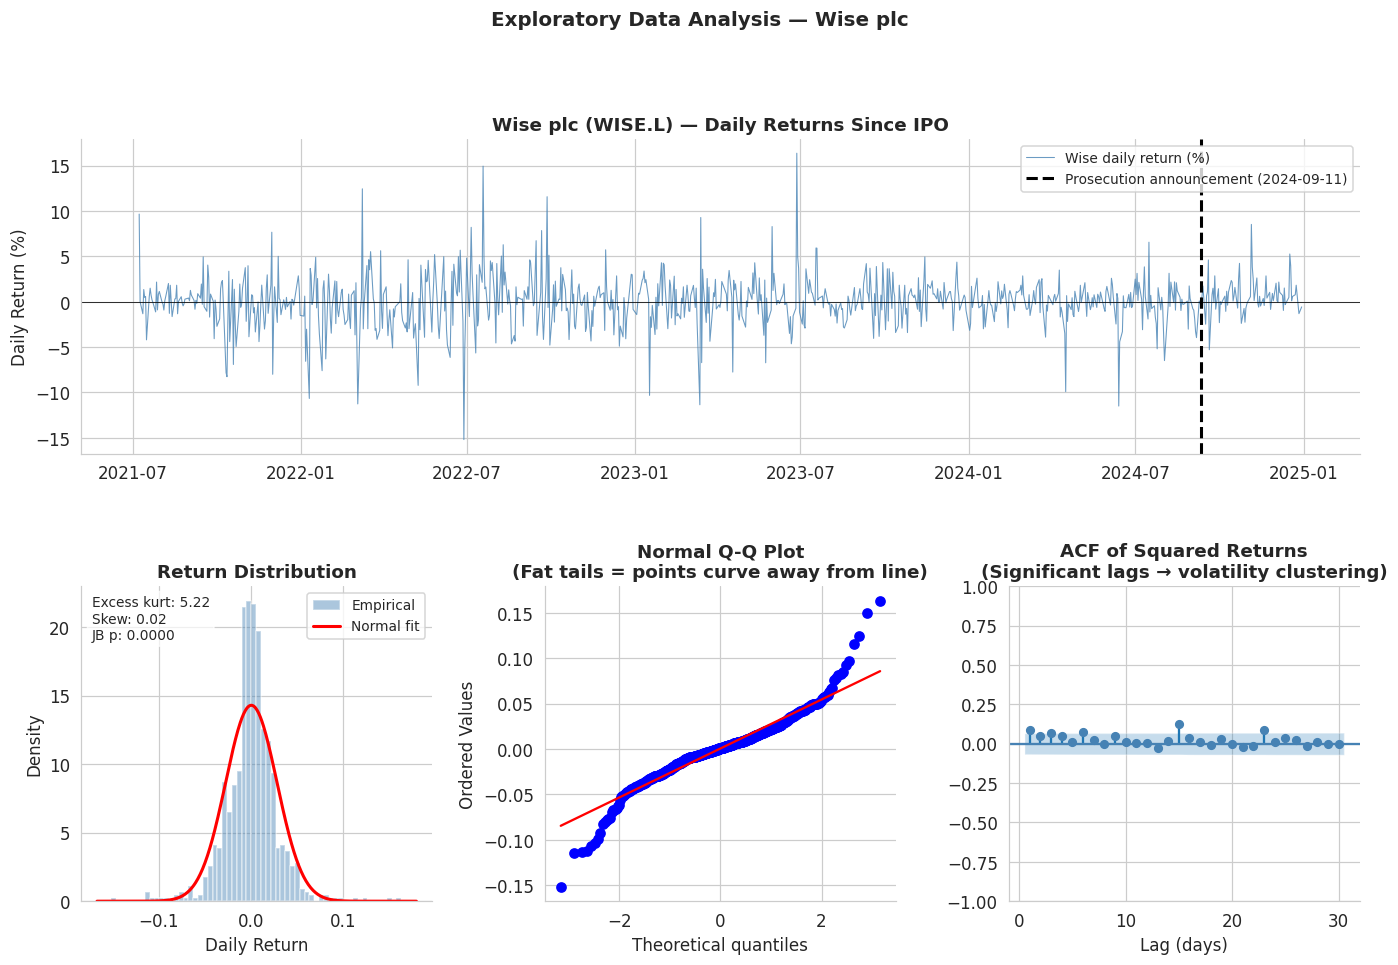

Excess kurtosis : 5.2197  (fat-tailed)
Skewness        : 0.0202  (right-skewed)
Jarque-Bera     : stat=995.66,  p=0.000000  → REJECT normality at 5%

In [3]:
skew     = stats.skew(wise_ret)
kurt     = stats.kurtosis(wise_ret, fisher=True)
jb, jb_p = stats.jarque_bera(wise_ret)

fig = plt.figure(figsize=(15, 9))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.42, wspace=0.32)

# ── Return time series ──────────────────────────────────────────────────────────
ax0 = fig.add_subplot(gs[0, :])
ax0.plot(wise_ret.index, wise_ret.values * 100,
         color=C['hist'], lw=0.7, alpha=0.8, label='Wise daily return (%)')
ax0.axvline(pd.Timestamp(EVENT_DATE), color=C['event'], lw=2, ls='--',
            label=f'Prosecution announcement ({EVENT_DATE})')
ax0.axhline(0, color='black', lw=0.5)
ax0.set_ylabel('Daily Return (%)')
ax0.set_title('Wise plc (WISE.L) — Daily Returns Since IPO', fontweight='bold')
ax0.legend()

# ── Return histogram vs Normal ──────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[1, 0])
x   = np.linspace(wise_ret.min() * 1.1, wise_ret.max() * 1.1, 400)
ax1.hist(wise_ret, bins=60, density=True,
         color=C['hist'], alpha=0.45, label='Empirical')
ax1.plot(x, norm.pdf(x, wise_ret.mean(), wise_ret.std()), 'r-', lw=2,
         label='Normal fit')
ax1.set_xlabel('Daily Return'); ax1.set_ylabel('Density')
ax1.set_title('Return Distribution', fontweight='bold')
ax1.legend()
ax1.text(0.03, 0.97,
         f'Excess kurt: {kurt:.2f}\nSkew: {skew:.2f}\nJB p: {jb_p:.4f}',
         transform=ax1.transAxes, va='top', fontsize=9,
         bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.7))

# ── Normal Q-Q plot ─────────────────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1, 1])
stats.probplot(wise_ret, dist='norm', plot=ax2)
ax2.set_title('Normal Q-Q Plot\n(Fat tails = points curve away from line)', fontweight='bold')
ax2.get_lines()[1].set_color('red')

# ── ACF of squared returns ──────────────────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 2])
sm.graphics.tsa.plot_acf(wise_ret**2, lags=30, ax=ax3, alpha=0.05,
                          color=C['hist'], zero=False)
ax3.set_title('ACF of Squared Returns\n(Significant lags → volatility clustering)', fontweight='bold')
ax3.set_xlabel('Lag (days)')

plt.suptitle('Exploratory Data Analysis — Wise plc', fontsize=13, fontweight='bold', y=1.01)
plt.savefig('01_eda_wise.png', bbox_inches='tight')
plt.show()

print(f'Excess kurtosis : {kurt:.4f}  ({"fat-tailed" if kurt > 1 else "near-normal"})')
print(f'Skewness        : {skew:.4f}  ({"left-skewed (downside risk)" if skew < 0 else "right-skewed"})')
print(f'Jarque-Bera     : stat={jb:.2f},  p={jb_p:.6f}  '
      f'→ {"REJECT normality" if jb_p < 0.05 else "Cannot reject normality"} at 5%')

## 3. Risk Measure Functions

All three estimation methods follow the lecture notation where $\mathcal{L} = -R_t$ is the loss (negative of return):

$$\text{VaR}_\alpha = \inf\{x : P(\mathcal{L} > x) \leq \alpha\}, \qquad \text{ES}_\alpha = E[\mathcal{L} \mid \mathcal{L} \geq \text{VaR}_\alpha]$$

**Normal**: $\text{VaR}^N_\alpha = -(\hat\mu + \hat\sigma\,\Phi^{-1}(\alpha))$, $\quad\text{ES}^N_\alpha = -\hat\mu + \hat\sigma\,\frac{\phi(\Phi^{-1}(\alpha))}{\alpha}$

**Student-t** (MLE fit): $\text{VaR}^t_\alpha = -(\hat\mu + \hat\lambda\,t_\nu^{-1}(\alpha))$, $\quad\text{ES}^t_\alpha = \hat\lambda\,\frac{f_\nu(t_\nu^{-1}(\alpha))}{\alpha}\cdot\frac{\nu + (t_\nu^{-1}(\alpha))^2}{\nu-1} - \hat\mu$

In [4]:
# ── Nonparametric (Historical) ──────────────────────────────────────────────────
def nonparametric_var_es(returns, alpha):
    """Historical VaR and ES. No distributional assumption."""
    losses = -np.asarray(returns)
    var    = np.percentile(losses, (1 - alpha) * 100)
    es     = losses[losses >= var].mean()
    return float(var), float(es)


# ── Parametric Normal ───────────────────────────────────────────────────────────
def parametric_normal_var_es(mu, sigma, alpha):
    """VaR and ES under Normal(mu, sigma) for loss = -return."""
    q   = norm.ppf(alpha)
    var = -(mu + sigma * q)
    es  = -mu + sigma * norm.pdf(q) / alpha
    return float(var), float(es)


# ── Parametric Student-t (MLE) ──────────────────────────────────────────────────
def parametric_t_var_es(mu, lam, nu, alpha):
    """VaR and ES under scaled t(nu) with location mu and scale lam."""
    q_std = t_dist.ppf(alpha, df=nu)
    var   = -(mu + lam * q_std)
    f_q   = t_dist.pdf(q_std, df=nu)
    es    = lam * (f_q / alpha) * (nu + q_std**2) / (nu - 1) - mu
    return float(var), float(es)


# ── Fit parameters ──────────────────────────────────────────────────────────────
mu_n, sigma_n    = wise_ret.mean(), wise_ret.std(ddof=1)
nu_t, mu_t, lam_t = t_dist.fit(wise_ret)

print(f'Normal MLE:   μ = {mu_n:.6f},  σ = {sigma_n:.6f}')
print(f't-dist MLE:   μ = {mu_t:.6f},  λ = {lam_t:.6f},  ν = {nu_t:.2f}')
print(f'\nNote: ν = {nu_t:.1f} degrees of freedom.'
      f'{" Heavy fat tails" if nu_t < 5 else " Moderate fat tails" if nu_t < 10 else " Near-normal"}'
      f' (Normal → ν = ∞).')
print('Low ν confirms Normal VaR will underestimate tail risk for Wise.')

print('\nRisk measure functions defined.')

Normal MLE:   μ = 0.000585,  σ = 0.027909
t-dist MLE:   μ = 0.000895,  λ = 0.017691,  ν = 3.02

Note: ν = 3.0 degrees of freedom. Heavy fat tails (Normal → ν = ∞).
Low ν confirms Normal VaR will underestimate tail risk for Wise.

Risk measure functions defined.

## 4. VaR and ES — All Methods Compared

We report across three α levels: **5%** (primary), **2.5%** (Basel III/FRTB regulatory standard for CVaR), **1%** (original Basel II standard).

Key diagnostic: if Normal VaR diverges substantially from Student-t VaR at lower α levels, this confirms fat-tailed returns and that the normal assumption materially underestimates Wise's tail risk.

In [5]:
# ── Compute all methods ─────────────────────────────────────────────────────────
res = {}
for a in ALPHAS:
    h_var, h_es          = nonparametric_var_es(wise_ret, a)
    n_var, n_es          = parametric_normal_var_es(mu_n, sigma_n, a)
    t_var, t_es          = parametric_t_var_es(mu_t, lam_t, nu_t, a)
    res[a] = dict(h_var=h_var, h_es=h_es,
                  n_var=n_var, n_es=n_es,
                  t_var=t_var, t_es=t_es)

# ── Print comparison table (mirrors professor's format exactly) ─────────────────
print(f'\n{"Method":<20} {"α=5%":>10} {"α=2.5%":>10} {"α=1%":>10}')
print('=' * 54)
for label, keys in [
    ('Nonpar VaR',  ('h_var', 'h_var',  'h_var')),
    ('Nonpar ES',   ('h_es',  'h_es',   'h_es')),
    ('',            None),
    ('Normal VaR',  ('n_var', 'n_var',  'n_var')),
    ('Normal ES',   ('n_es',  'n_es',   'n_es')),
    ('',            None),
    ('t-dist VaR',  ('t_var', 't_var',  't_var')),
    ('t-dist ES',   ('t_es',  't_es',   't_es')),
]:
    if keys is None:
        print()
        continue
    row = [res[a][keys[0]] * 100 for a in ALPHAS]
    print(f'{label:<20} {row[0]:>9.3f}% {row[1]:>9.3f}% {row[2]:>9.3f}%')
print()

# ── Normal vs t-dist gap ─────────────────────────────────────────────────────────
print('Normal vs Student-t VaR gap (t − Normal):')
for a in ALPHAS:
    gap = (res[a]['t_var'] - res[a]['n_var']) * 100
    print(f'  α={a:.1%}: {gap:+.3f}% — '
          f'{"Normal substantially underestimates" if gap > 0.2 else "methods broadly agree"}')


Method                     α=5%     α=2.5%       α=1%
Nonpar VaR               4.078%     5.203%     8.065%
Nonpar ES                6.503%     8.442%    10.857%

Normal VaR               4.532%     5.412%     6.434%
Normal ES                5.698%     6.466%     7.380%

t-dist VaR               4.065%     5.525%     7.911%
t-dist ES                6.737%     8.782%    12.223%

Normal vs Student-t VaR gap (t − Normal):
  α=5.0%: -0.467% — methods broadly agree
  α=2.5%: +0.113% — methods broadly agree
  α=1.0%: +1.477% — Normal substantially underestimates

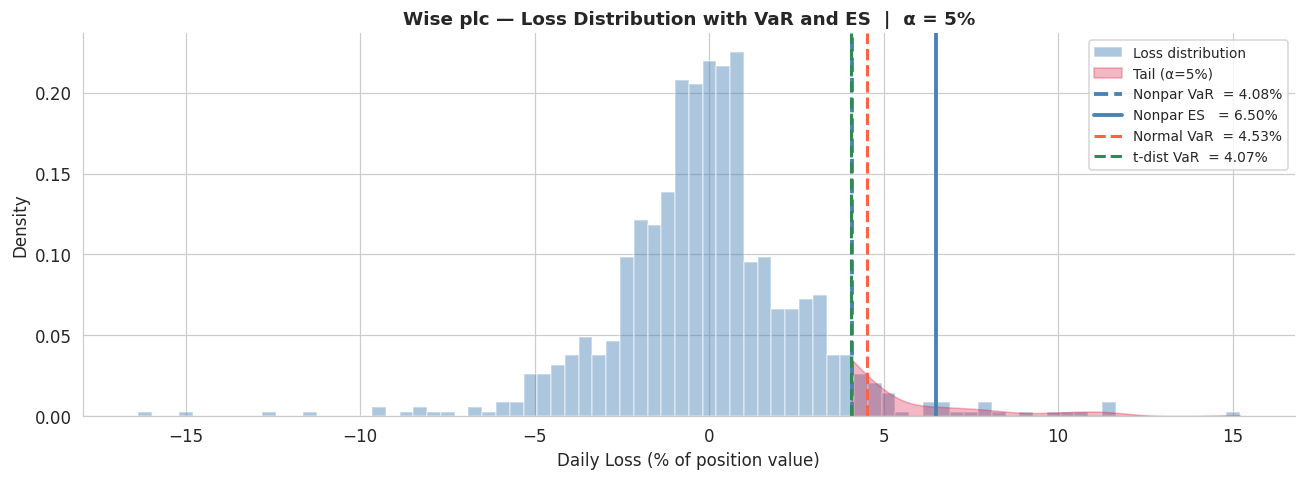

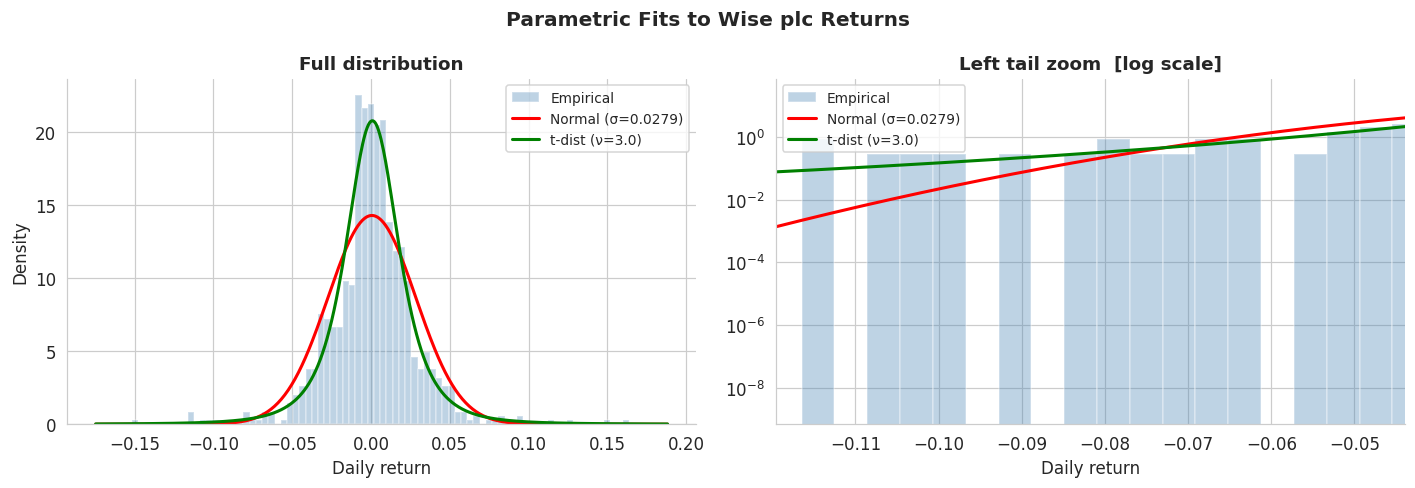

In the tail zoom (log scale), the t-distribution closely tracks the empirical
density, while the Normal distribution underestimates the probability of large losses.

In [6]:
# ── Figure 1: Loss distribution with VaR and ES marked ─────────────────────────
# Mirrors professor's np_var_es.png plot exactly, extended to show all methods
losses       = -wise_ret.values
alpha_plot   = ALPHA_MAIN
h_var, h_es  = nonparametric_var_es(wise_ret, alpha_plot)
n_var, n_es  = parametric_normal_var_es(mu_n, sigma_n, alpha_plot)
t_var, t_es  = parametric_t_var_es(mu_t, lam_t, nu_t, alpha_plot)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.hist(losses * 100, bins=80, density=True,
        color=C['hist'], alpha=0.45, label='Loss distribution')

# Shade the tail beyond historical VaR
x_fill = np.linspace(h_var * 100, losses.max() * 100, 300)
kde    = stats.gaussian_kde(losses * 100)
ax.fill_between(x_fill, kde(x_fill), alpha=0.30,
                color=C['tail'], label=f'Tail (α={alpha_plot:.0%})')

ax.axvline(h_var * 100, color=C['hist'],   lw=2.5, ls='--',
           label=f'Nonpar VaR  = {h_var:.2%}')
ax.axvline(h_es  * 100, color=C['hist'],   lw=2.5, ls='-',
           label=f'Nonpar ES   = {h_es:.2%}')
ax.axvline(n_var * 100, color=C['normal'], lw=2,   ls='--',
           label=f'Normal VaR  = {n_var:.2%}')
ax.axvline(t_var * 100, color=C['tdist'],  lw=2,   ls='--',
           label=f't-dist VaR  = {t_var:.2%}')

ax.set_xlabel('Daily Loss (% of position value)')
ax.set_ylabel('Density')
ax.set_title(f'Wise plc — Loss Distribution with VaR and ES  |  α = {alpha_plot:.0%}',
             fontweight='bold')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('02_loss_distribution.png', bbox_inches='tight')
plt.show()

# ── Figure 2: Parametric fits — full + tail zoom (mirrors professor exactly) ────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.linspace(wise_ret.min() * 1.15, wise_ret.max() * 1.15, 500)

for ax, title, xlim in zip(
    axes,
    ['Full distribution', 'Left tail zoom'],
    [None, (wise_ret.quantile(0.001), wise_ret.quantile(0.04))]
):
    ax.hist(wise_ret, bins=80, density=True,
            color=C['hist'], alpha=0.35, label='Empirical')
    ax.plot(x, norm.pdf(x, mu_n, sigma_n), 'r-', lw=2,
            label=f'Normal (σ={sigma_n:.4f})')
    ax.plot(x, t_dist.pdf(x, nu_t, mu_t, lam_t), 'g-', lw=2,
            label=f't-dist (ν={nu_t:.1f})')
    ax.set_xlabel('Daily return')
    ax.legend()
    if xlim:
        ax.set_xlim(xlim)
        ax.set_yscale('log')
        ax.set_title(f'{title}  [log scale]', fontweight='bold')
    else:
        ax.set_title(title, fontweight='bold')

axes[0].set_ylabel('Density')
plt.suptitle('Parametric Fits to Wise plc Returns', fontweight='bold')
plt.tight_layout()
plt.savefig('03_parametric_fits.png', bbox_inches='tight')
plt.show()
print('In the tail zoom (log scale), the t-distribution closely tracks the empirical')
print('density, while the Normal distribution underestimates the probability of large losses.')

## 5. Bootstrap Confidence Intervals

The estimates above are *themselves* random variables — different samples give different answers. We use the **bootstrap** to quantify estimation uncertainty:

1. Draw a resample of size $n$ **with replacement** from the original returns
2. Compute VaR and ES from the resample
3. Repeat $B = 5{,}000$ times
4. 95% CI = [2.5th percentile, 97.5th percentile] of the bootstrap distribution

> A wide CI signals that we do not have enough tail observations to reliably estimate these quantities — particularly relevant at α = 1% where only ~8 observations fall in the tail.

In [7]:
def bootstrap_ci(returns, alpha, B=5000, ci_level=0.95):
    """Bootstrap CIs for nonparametric VaR and ES."""
    n        = len(returns)
    ret_arr  = np.asarray(returns)
    boot_var = np.zeros(B)
    boot_es  = np.zeros(B)
    for b in range(B):
        s             = ret_arr[np.random.choice(n, n, replace=True)]
        boot_var[b], boot_es[b] = nonparametric_var_es(s, alpha)
    tail   = (1 - ci_level) / 2
    var_ci = (np.quantile(boot_var, tail), np.quantile(boot_var, 1 - tail))
    es_ci  = (np.quantile(boot_es,  tail), np.quantile(boot_es,  1 - tail))
    var_pt, es_pt = nonparametric_var_es(returns, alpha)
    return dict(var_pt=var_pt, var_ci=var_ci, bvar=boot_var,
                es_pt=es_pt,  es_ci=es_ci,  bes=boot_es)


print('Running bootstrap (B=5000) — takes ~30 seconds...')
boot = {a: bootstrap_ci(wise_ret, a, B=5000) for a in ALPHAS}
print('Done.\n')

print(f'Bootstrap 95% CIs (B=5000) — point estimates and [lower, upper]')
print(f'{"Alpha":>8}  {"VaR":>8}  {"CI lower":>10}  {"CI upper":>10}  {"CI width":>10}')
print('-' * 56)
for a in ALPHAS:
    r     = boot[a]
    width = r['var_ci'][1] - r['var_ci'][0]
    print(f'{a:>8.1%}  {r["var_pt"]:>8.4%}  [{r["var_ci"][0]:>8.4%},  {r["var_ci"][1]:>8.4%}]  width={width:.4%}')
print()
print(f'{"Alpha":>8}  {"ES":>8}  {"CI lower":>10}  {"CI upper":>10}  {"CI width":>10}')
print('-' * 56)
for a in ALPHAS:
    r     = boot[a]
    width = r['es_ci'][1] - r['es_ci'][0]
    print(f'{a:>8.1%}  {r["es_pt"]:>8.4%}  [{r["es_ci"][0]:>8.4%},  {r["es_ci"][1]:>8.4%}]  width={width:.4%}')

Running bootstrap (B=5000) — takes ~30 seconds...
Done.

Bootstrap 95% CIs (B=5000) — point estimates and [lower, upper]
   Alpha       VaR    CI lower    CI upper    CI width
--------------------------------------------------------
    5.0%   4.0783%  [ 3.7093%,   4.4464%]  width=0.7370%
    2.5%   5.2032%  [ 4.4546%,   6.7508%]  width=2.2962%
    1.0%   8.0647%  [ 6.5670%,  10.6659%]  width=4.0989%

   Alpha        ES    CI lower    CI upper    CI width
--------------------------------------------------------
    5.0%   6.5033%  [ 5.4864%,   7.5073%]  width=2.0209%
    2.5%   8.4418%  [ 6.7914%,   9.9098%]  width=3.1184%
    1.0%  10.8570%  [ 8.6281%,  12.4625%]  width=3.8345%

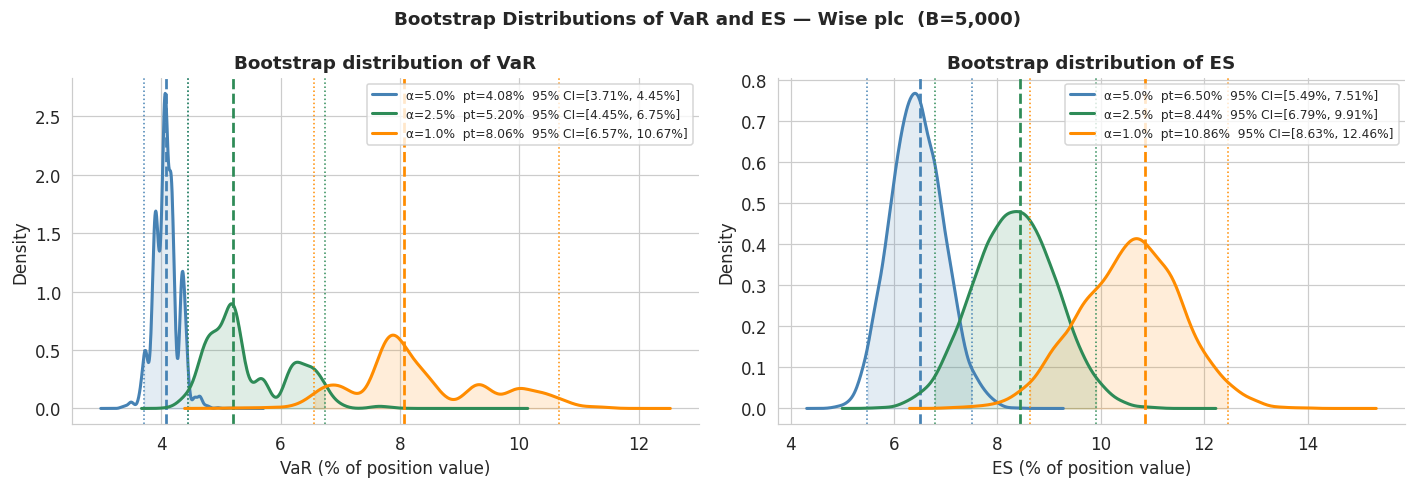

In [8]:
# ── Figure 3: Bootstrap distributions (mirrors professor's bootstrap_ci.png) ────
colors_boot = {0.05: 'steelblue', 0.025: 'seagreen', 0.01: 'darkorange'}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fig.suptitle('Bootstrap Distributions of VaR and ES — Wise plc  (B=5,000)',
             fontweight='bold', fontsize=12)

for ax, (bkey, ylabel) in zip(axes, [('bvar', 'VaR'), ('bes', 'ES')]):
    ptkey = bkey.replace('b', '') + '_pt'
    cikey = bkey.replace('b', '') + '_ci'
    for a in ALPHAS:
        r     = boot[a]
        pts   = r[bkey] * 100
        pt    = r[ptkey] * 100
        lo, hi = r[cikey][0]*100, r[cikey][1]*100
        kde   = stats.gaussian_kde(pts, bw_method='scott')
        xg    = np.linspace(pts.min()*0.9, pts.max()*1.1, 400)
        dens  = kde(xg)
        lbl   = f'α={a:.1%}  pt={pt:.2f}%  95% CI=[{lo:.2f}%, {hi:.2f}%]'
        ax.plot(xg, dens, lw=2, color=colors_boot[a], label=lbl)
        ax.fill_between(xg, dens, where=(xg >= lo) & (xg <= hi),
                        alpha=0.15, color=colors_boot[a])
        ax.axvline(pt, color=colors_boot[a], lw=1.8, ls='--')
        ax.axvline(lo, color=colors_boot[a], lw=1.0, ls=':')
        ax.axvline(hi, color=colors_boot[a], lw=1.0, ls=':')
    ax.set_xlabel(f'{ylabel} (% of position value)')
    ax.set_ylabel('Density')
    ax.set_title(f'Bootstrap distribution of {ylabel}', fontweight='bold')
    ax.legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.savefig('04_bootstrap_ci.png', bbox_inches='tight')
plt.show()

## 6. Kupiec POF Backtesting

Backtesting tests whether the observed breach rate matches the theoretical α — this is a **Basel III regulatory requirement** for internal risk models.

**Kupiec Proportion of Failures (POF):** $H_0$: breach probability = $\alpha$. Test statistic is likelihood-ratio based, $\chi^2(1)$ under $H_0$. Reject if p-value < 0.05 (model mis-specified).

In [10]:
def kupiec_pof(returns, alpha, window=ROLLING_WIN):
    """Kupiec Proportion of Failures backtest using rolling historical VaR."""
    ret = np.asarray(returns)
    n   = len(ret)
    var_series = np.array([
        nonparametric_var_es(ret[:i], alpha)[0]
        for i in range(window, n)  # Changed range from n + 1 to n
    ])
    losses_test = -ret[window:]
    T           = len(var_series)
    breaches    = int(np.sum(losses_test > var_series))
    p_hat       = breaches / T
    if 0 < p_hat < 1:
        lr  = -2 * (breaches * np.log(alpha / p_hat) +
                    (T - breaches) * np.log((1 - alpha) / (1 - p_hat)))
        pv  = 1 - stats.chi2.cdf(lr, df=1)
    else:
        lr, pv = np.nan, np.nan
    return dict(T=T, breaches=breaches, p_hat=p_hat,
                lr=lr, pval=pv,
                passed=pv > 0.05 if not np.isnan(pv) else None,
                var_series=var_series,
                losses_test=losses_test)

kup = {a: kupiec_pof(wise_ret, a) for a in ALPHAS}

print(f'{'α':>6}  {'T':>5}  {'Breaches':>9}  {'Obs rate':>9}  {'Exp rate':>9}  {'LR stat':>8}  {'p-val':>7}  {'Result':>7}')
print('─' * 72)
for a in ALPHAS:
    k  = kup[a]
    ok = '✓ PASS' if k['passed'] else '✗ FAIL'
    print(f'{a:>6.1%}  {k['T']:>5}  {k['breaches']:>9}  '
          f'{k['p_hat']:>9.4f}  {a:>9.4f}  '
          f'{k['lr']:>8.3f}  {k['pval']:>7.4f}  {ok:>7}')

     α      T   Breaches   Obs rate   Exp rate   LR stat    p-val   Result
────────────────────────────────────────────────────────────────────────
  5.0%    627         13     0.0207     0.0500    14.373   0.0001   ✗ FAIL
  2.5%    627          7     0.0112     0.0250     6.186   0.0129   ✗ FAIL
  1.0%    627          4     0.0064     0.0100     0.952   0.3291   ✓ PASS

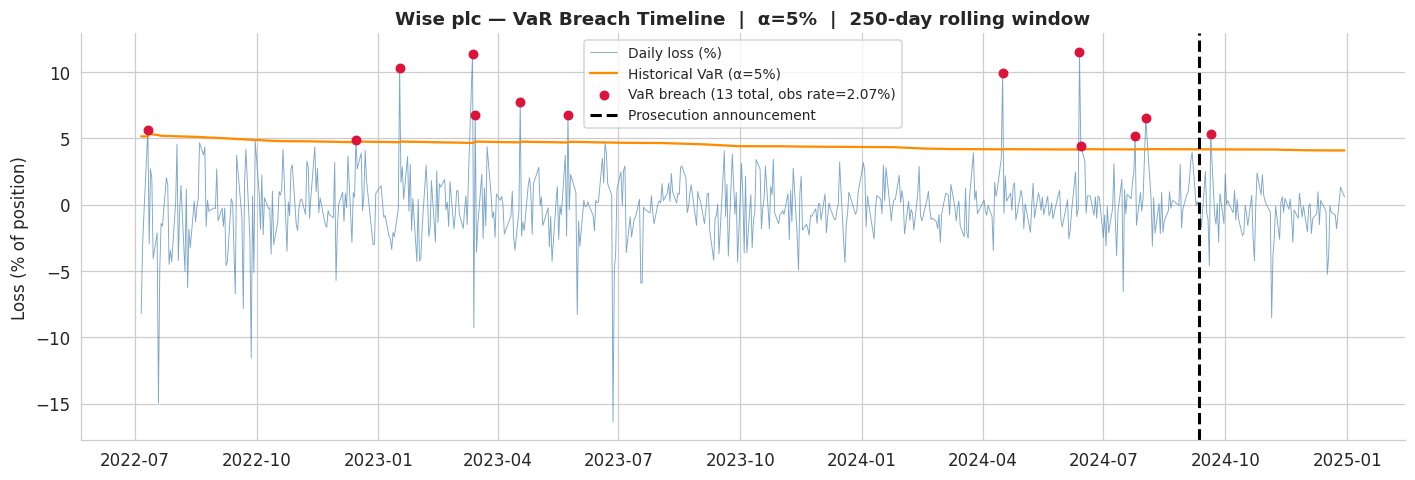

In [11]:
# ── Figure 4: VaR breach timeline ──────────────────────────────────────────────
k5          = kup[ALPHA_MAIN]
dates_test  = wise_ret.index[ROLLING_WIN:]
breach_mask = k5['losses_test'] > k5['var_series']

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(dates_test, k5['losses_test'] * 100,
        color=C['hist'], lw=0.6, alpha=0.7, label='Daily loss (%)')
ax.plot(dates_test, k5['var_series'] * 100,
        color=C['static'], lw=1.5, label=f'Historical VaR (α={ALPHA_MAIN:.0%})')
ax.scatter(dates_test[breach_mask], k5['losses_test'][breach_mask] * 100,
           color=C['tail'], s=30, zorder=5,
           label=f'VaR breach ({breach_mask.sum()} total, obs rate={k5["p_hat"]:.2%})')
ax.axvline(pd.Timestamp(EVENT_DATE), color=C['event'], lw=2, ls='--',
           label='Prosecution announcement')
ax.set_ylabel('Loss (% of position)')
ax.set_title(f'Wise plc — VaR Breach Timeline  |  α={ALPHA_MAIN:.0%}  |  {ROLLING_WIN}-day rolling window',
             fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('05_var_breaches.png', bbox_inches='tight')
plt.show()

## 7. GARCH(1,1) — Time-Varying VaR and ES

The static methods above produce a **single number** regardless of whether markets are calm or in crisis. But the ACF of squared returns shows volatility clustering — periods of high volatility tend to be followed by more high volatility.

**GARCH(1,1)** model for the conditional variance:
$$R_t = \mu + \epsilon_t, \quad \epsilon_t = \sigma_t z_t, \quad z_t \overset{\text{i.i.d.}}{\sim} t(\nu)$$
$$\sigma_t^2 = \omega + \alpha_1 \epsilon_{t-1}^2 + \beta_1 \sigma_{t-1}^2$$

After fitting, the one-step-ahead dynamic VaR is:
$$\text{VaR}^\text{GARCH}_{t+1}(\alpha) = -(\hat\mu + \hat\sigma_{t+1} \cdot t_\nu^{-1}(\alpha))$$

**EMH connection:** A GARCH VaR spike concentrated on the prosecution announcement date is consistent with semi-strong EMH — the market instantly repricing risk on new public information.

In [12]:
# ── Fit GARCH(1,1) with Student-t innovations ───────────────────────────────────
ret_pct   = wise_ret * 100   # scale to % for numerical stability
gm        = arch_model(ret_pct, mean='Constant', vol='GARCH', p=1, q=1, dist='StudentsT')
gfit      = gm.fit(disp='off')
print(gfit.summary())

mu_g      = gfit.params['mu']
nu_g      = gfit.params['nu']
cond_vol  = gfit.conditional_volatility   # in % units
a1        = gfit.params['alpha[1]']
b1        = gfit.params['beta[1]']

print(f'\nPersistence (α+β): {a1+b1:.4f} — '
      f'{"high persistence, shocks decay slowly" if a1+b1 > 0.95 else "moderate persistence"}')

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                         WISE   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -2021.47
Distribution:      Standardized Student's t   AIC:                           4052.93
Method:                  Maximum Likelihood   BIC:                           4076.81
                                              No. Observations:                  877
Date:                      Wed, Jun 10 2026   Df Residuals:                      876
Time:                              00:12:48   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

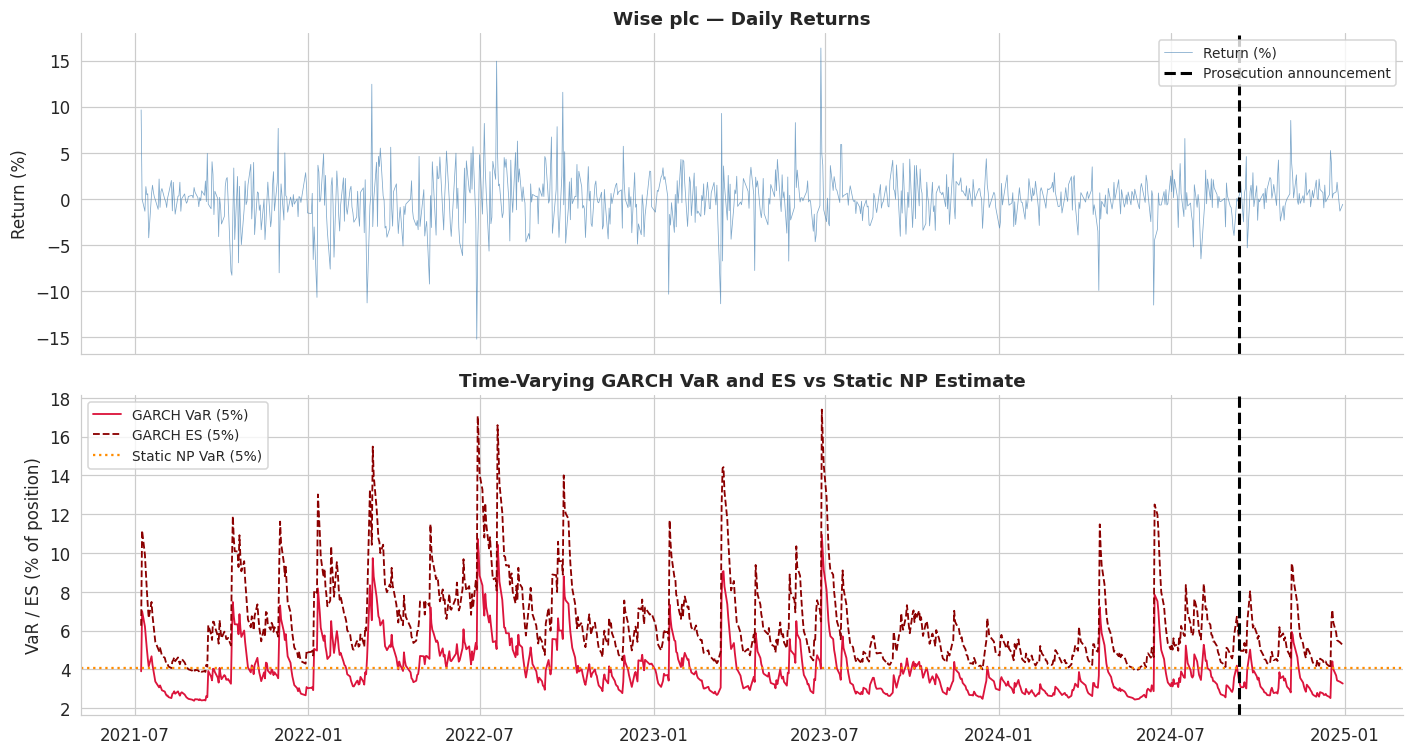

Key insight: GARCH VaR/ES spikes during periods of high volatility and shrinks during calm periods.
A static estimate understates risk during crises and overstates it when markets are calm.

Peak GARCH VaR in ±10-day event window: 4.192% (on 2024-09-09)
Static NP VaR (full sample):                   4.078%
Ratio peak/static:                             1.03x

In [13]:
# ── Compute GARCH time-varying VaR and ES series ────────────────────────────────
alpha_g      = ALPHA_MAIN
q_std        = t_dist.ppf(alpha_g, df=nu_g)
f_q          = t_dist.pdf(q_std, df=nu_g)
scale_series = cond_vol / np.sqrt(nu_g / (nu_g - 2))  # standardised scale

garch_var = -(mu_g + scale_series * q_std) / 100      # decimal
garch_es  = (scale_series * (f_q / alpha_g) *
             (nu_g + q_std**2) / (nu_g - 1) - mu_g) / 100

static_var_np, static_es_np = nonparametric_var_es(wise_ret, alpha_g)

# ── Figure 5: GARCH VaR (mirrors professor's garch_var_es.png exactly) ──────────
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

axes[0].plot(wise_ret.index, wise_ret.values * 100,
             color=C['hist'], lw=0.5, alpha=0.7, label='Return (%)')
axes[0].axvline(pd.Timestamp(EVENT_DATE), color=C['event'], lw=2, ls='--',
                label='Prosecution announcement')
axes[0].set_ylabel('Return (%)')
axes[0].set_title('Wise plc — Daily Returns', fontweight='bold')
axes[0].legend(loc='upper right')

axes[1].plot(garch_var.index, garch_var.values * 100,
             color=C['garch'],    lw=1.2, label=f'GARCH VaR ({alpha_g:.0%})')
axes[1].plot(garch_es.index,  garch_es.values  * 100,
             color=C['garch_es'], lw=1.2, ls='--', label=f'GARCH ES ({alpha_g:.0%})')
axes[1].axhline(static_var_np * 100, color=C['static'], lw=1.5, ls=':',
                label=f'Static NP VaR ({alpha_g:.0%})')
axes[1].axvline(pd.Timestamp(EVENT_DATE), color=C['event'], lw=2, ls='--')
axes[1].set_ylabel('VaR / ES (% of position)')
axes[1].set_title('Time-Varying GARCH VaR and ES vs Static NP Estimate', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('06_garch_var_es.png', bbox_inches='tight')
plt.show()

print('Key insight: GARCH VaR/ES spikes during periods of high volatility and shrinks during calm periods.')
print('A static estimate understates risk during crises and overstates it when markets are calm.')

# ── Peak GARCH VaR around event ──────────────────────────────────────────────────
event_dt = pd.Timestamp(EVENT_DATE)
win_idx  = [d for d in garch_var.index
            if event_dt - pd.Timedelta(days=EVENT_WIN) <= d <= event_dt + pd.Timedelta(days=EVENT_WIN)]
if win_idx:
    peak_var  = garch_var.loc[win_idx].max() * 100
    peak_date = garch_var.loc[win_idx].idxmax()
    print(f'\nPeak GARCH VaR in ±{EVENT_WIN}-day event window: {peak_var:.3f}% (on {peak_date.date()})')
    print(f'Static NP VaR (full sample):                   {static_var_np*100:.3f}%')
    print(f'Ratio peak/static:                             {peak_var/(static_var_np*100):.2f}x')

## 8. Event Study — Belgian Prosecution Announcement

The event study isolates the **abnormal return** attributable to the prosecution announcement by subtracting the sector benchmark return (the normal return model):

$$AR_t = R_t^{\text{WISE}} - R_t^{\text{SECTOR}}, \qquad CAR = \sum_{t \in \text{window}} AR_t$$

**EMH interpretation:** Under semi-strong EMH, the price adjustment should be immediate and concentrated on day 0. Pre-announcement drift suggests information leakage; prolonged post-announcement drift suggests market under-reaction.

In [15]:
# ── Download sector data ────────────────────────────────────────────────────────
print('Downloading peer firms for sector benchmark...')
peer_rets = {}
for t in PEER_TICKERS:
    # Attempt download
    r = yf.download(t, start=START_DATE, end=END_DATE, progress=False)
    # Check if download was successful and has data
    if not r.empty and 'Close' in r.columns:
        p = r['Close'].squeeze().pct_change().dropna()
        # Ensure the series is not empty after processing
        if not p.empty:
            p.name = t
            peer_rets[t] = p
        else:
            print(f"Skipping {t}: No valid returns after processing.")
    else:
        print(f"Skipping {t}: Download failed or no 'Close' column found.")

# Now peer_df will only contain valid return series
peer_df    = pd.DataFrame(peer_rets).dropna()
sector_ret = peer_df.mean(axis=1)
sector_ret.name = 'SECTOR'

combined   = pd.concat([wise_ret, sector_ret], axis=1).dropna()
wise_a     = combined['WISE']
sector_a   = combined['SECTOR']
abnormal   = wise_a - sector_a

# ── Locate event trading day ────────────────────────────────────────────────────
all_dates  = wise_a.index
event_dt   = pd.Timestamp(EVENT_DATE)
eidx       = all_dates.searchsorted(event_dt)
eidx       = min(eidx, len(all_dates) - 1)
event_act  = all_dates[eidx]

print(f'Event date specified:  {EVENT_DATE}')
print(f'Nearest trading day:   {event_act.date()}')

s_idx = max(0, eidx - EVENT_WIN)
e_idx = min(len(all_dates), eidx + EVENT_WIN + 1)
wdates   = all_dates[s_idx:e_idx]
w_wise   = wise_a.loc[wdates]
w_sector = sector_a.loc[wdates]
w_ar     = abnormal.loc[wdates]
w_car    = w_ar.cumsum()
rel_days = np.arange(-EVENT_WIN, EVENT_WIN + 1)[:len(wdates)]

Skipping SQ: Download failed or no 'Close' column found.
Event date specified:  2024-09-11
Nearest trading day:   2024-09-11

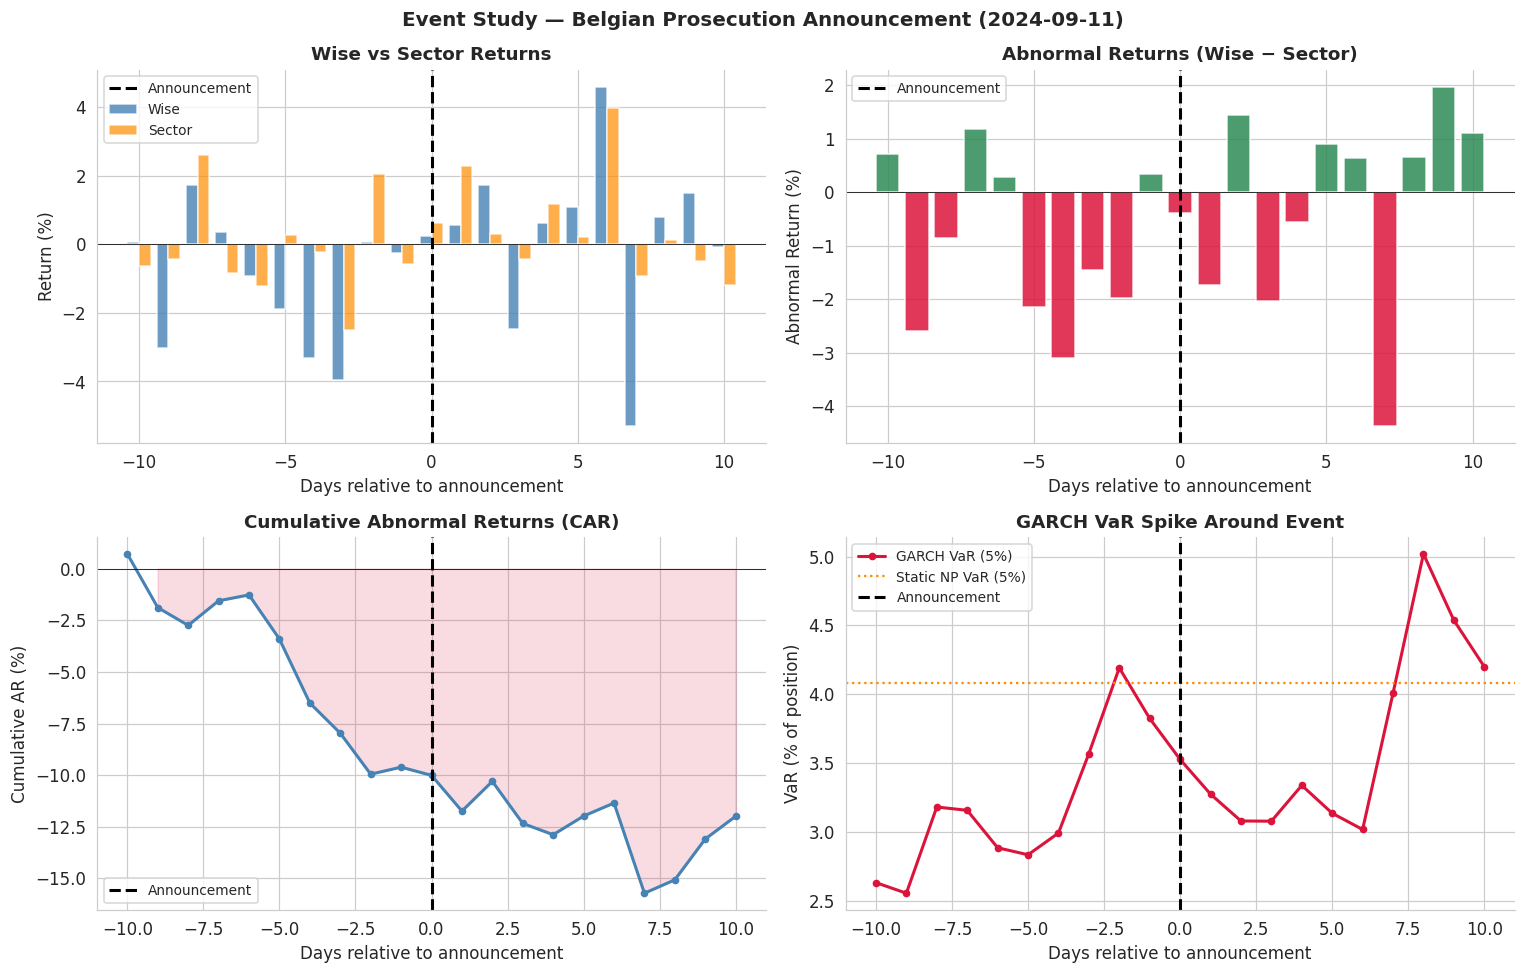


Announcement day statistics:
  Wise return (day 0):       0.238%
  Abnormal return (day 0):   -0.397%
  CAR [0, +3 days]:          -12.337%
  CAR [full window]:         -11.991%

EMH interpretation:
  Pre-event CAR:  -9.613% — possible leakage
  Post-event drift: -1.981% — under-reaction

In [16]:
# ── Figure 6: Event study 2x2 ───────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(f'Event Study — Belgian Prosecution Announcement ({EVENT_DATE})',
             fontsize=13, fontweight='bold')

# 1. Raw returns
ax = axes[0, 0]
ax.bar(rel_days - 0.2, w_wise.values   * 100, 0.4, label='Wise',   color=C['wise'],   alpha=0.8)
ax.bar(rel_days + 0.2, w_sector.values * 100, 0.4, label='Sector', color=C['sector'], alpha=0.7)
ax.axvline(0, color=C['event'], lw=2, ls='--', label='Announcement')
ax.axhline(0, color='black', lw=0.5)
ax.set_xlabel('Days relative to announcement')
ax.set_ylabel('Return (%)')
ax.set_title('Wise vs Sector Returns', fontweight='bold')
ax.legend()

# 2. Abnormal returns
ax = axes[0, 1]
bar_cols = [C['tail'] if v < 0 else C['tdist'] for v in w_ar.values]
ax.bar(rel_days, w_ar.values * 100, color=bar_cols, alpha=0.85)
ax.axvline(0, color=C['event'], lw=2, ls='--', label='Announcement')
ax.axhline(0, color='black', lw=0.5)
ax.set_xlabel('Days relative to announcement')
ax.set_ylabel('Abnormal Return (%)')
ax.set_title('Abnormal Returns (Wise − Sector)', fontweight='bold')
ax.legend()

# 3. Cumulative abnormal returns
ax = axes[1, 0]
ax.plot(rel_days, w_car.values * 100, color=C['wise'], lw=2, marker='o', ms=4)
ax.axvline(0, color=C['event'], lw=2, ls='--', label='Announcement')
ax.axhline(0, color='black', lw=0.5)
ax.fill_between(rel_days, w_car.values * 100, 0,
                where=(w_car.values < 0), alpha=0.15, color=C['tail'])
ax.set_xlabel('Days relative to announcement')
ax.set_ylabel('Cumulative AR (%)')
ax.set_title('Cumulative Abnormal Returns (CAR)', fontweight='bold')
ax.legend()

# 4. GARCH VaR around event
ax = axes[1, 1]
gv_window = garch_var.reindex(wdates, method='nearest') * 100
ax.plot(rel_days, gv_window.values, color=C['garch'], lw=2, marker='o', ms=4,
        label=f'GARCH VaR ({ALPHA_MAIN:.0%})')
ax.axhline(static_var_np * 100, color=C['static'], lw=1.5, ls=':',
           label=f'Static NP VaR ({ALPHA_MAIN:.0%})')
ax.axvline(0, color=C['event'], lw=2, ls='--', label='Announcement')
ax.set_xlabel('Days relative to announcement')
ax.set_ylabel('VaR (% of position)')
ax.set_title('GARCH VaR Spike Around Event', fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig('07_event_study.png', bbox_inches='tight')
plt.show()

# ── Print event statistics ──────────────────────────────────────────────────────
if 0 in rel_days:
    d0 = list(rel_days).index(0)
    print(f'\nAnnouncement day statistics:')
    print(f'  Wise return (day 0):       {w_wise.iloc[d0]*100:.3f}%')
    print(f'  Abnormal return (day 0):   {w_ar.iloc[d0]*100:.3f}%')
    print(f'  CAR [0, +3 days]:          {w_car.iloc[min(d0+3,len(w_car)-1)]*100:.3f}%')
    print(f'  CAR [full window]:         {w_car.iloc[-1]*100:.3f}%')
    print(f'\nEMH interpretation:')
    ar0 = w_ar.iloc[d0]
    pre_drift  = w_car.iloc[d0-1]*100 if d0 > 0 else 0
    post_drift = (w_car.iloc[-1] - w_car.iloc[d0])*100
    print(f'  Pre-event CAR:  {pre_drift:.3f}% — '
          f'{"possible leakage" if pre_drift < -0.5 else "no significant pre-announcement drift"}')
    print(f'  Post-event drift: {post_drift:.3f}% — '
          f'{"under-reaction" if post_drift < -0.5 else "broadly consistent with EMH"}')

---
# Part B — Sector Comparison
### Isolating Wise's Idiosyncratic Legal Risk

The sector benchmark (PYPL, SQ, ADYEN.AS, RELY — equal-weighted) serves as a reference point only. The question is whether Wise's tail risk exceeds sector-wide fintech risk, quantifying the **idiosyncratic premium** attributable to the legal shock.

Results are reported at α = 5% only, consistent with the sector benchmark's supporting rather than primary role in this analysis.

---

In [17]:
# ── VaR and ES: Wise vs Sector at primary alpha ─────────────────────────────────
a = ALPHA_MAIN
w_var, w_es = nonparametric_var_es(wise_a,   a)
s_var, s_es = nonparametric_var_es(sector_a, a)

print(f'Historical VaR and ES — Wise vs Sector Benchmark  (α={a:.0%})')
print('=' * 54)
print(f'{"":22} {"VaR":>12} {"ES (CVaR)":>12}')
print(f'{"Wise plc (WISE.L)":<22} {w_var*100:>11.3f}% {w_es*100:>11.3f}%')
print(f'{"Sector Benchmark":<22} {s_var*100:>11.3f}% {s_es*100:>11.3f}%')
print('─' * 54)
print(f'{"Idiosyncratic premium":<22} {(w_var-s_var)*100:>+11.3f}% {(w_es-s_es)*100:>+11.3f}%')
print()

# ── Pre vs post event ───────────────────────────────────────────────────────────
event_dt = pd.Timestamp(EVENT_DATE)
pre_wise = wise_a[wise_a.index < event_dt]
post_wise = wise_a[wise_a.index >= event_dt]

if len(pre_wise) > 30 and len(post_wise) > 5:
    pv, pe = nonparametric_var_es(pre_wise,  a)
    pov, poe = nonparametric_var_es(post_wise, a)
    print(f'Pre vs Post Prosecution — Wise  (α={a:.0%})')
    print('=' * 54)
    print(f'{"Period":<22} {"VaR":>12} {"ES":>12}  {"n":>5}')
    print(f'{"Pre-announcement":<22} {pv*100:>11.3f}% {pe*100:>11.3f}%  {len(pre_wise):>5}')
    print(f'{"Post-announcement":<22} {pov*100:>11.3f}% {poe*100:>11.3f}%  {len(post_wise):>5}')
    print(f'{"Change":<22} {(pov-pv)*100:>+11.3f}% {(poe-pe)*100:>+11.3f}%')

Historical VaR and ES — Wise vs Sector Benchmark  (α=5%)
                                VaR    ES (CVaR)
Wise plc (WISE.L)            4.160%       6.739%
Sector Benchmark             3.896%       5.822%
──────────────────────────────────────────────────────
Idiosyncratic premium       +0.265%      +0.916%

Pre vs Post Prosecution — Wise  (α=5%)
Period                          VaR           ES      n
Pre-announcement             4.343%       6.912%    724
Post-announcement            2.273%       3.118%     76
Change                      -2.070%      -3.795%

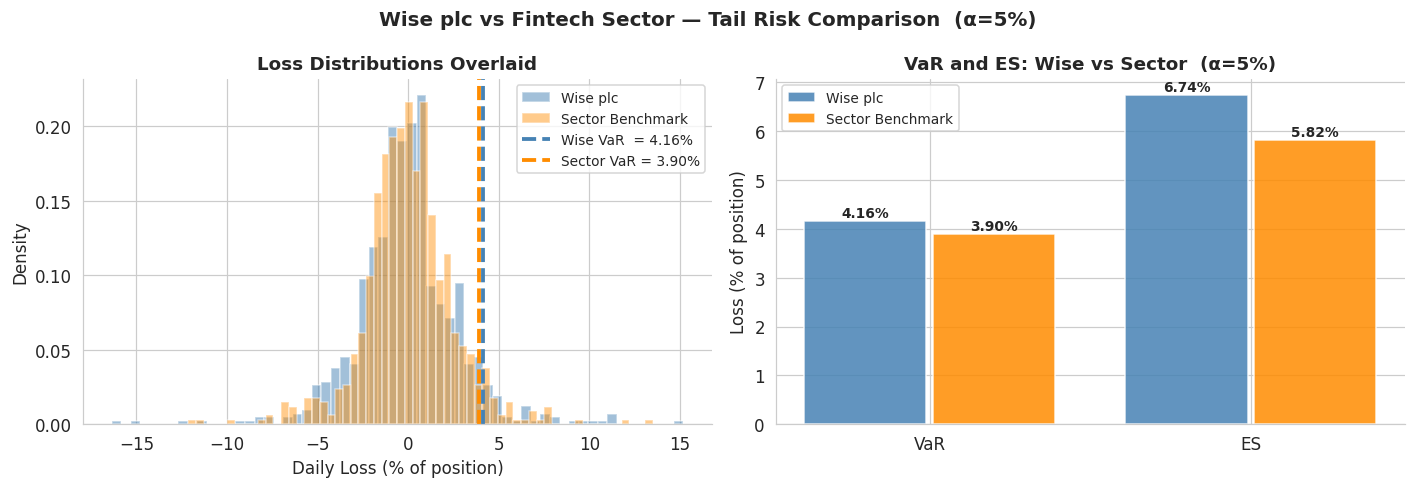

In [18]:
# ── Figure 7: Sector comparison 1x2 ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fig.suptitle('Wise plc vs Fintech Sector — Tail Risk Comparison  (α=5%)',
             fontsize=13, fontweight='bold')

# Left: loss distributions overlaid
ax = axes[0]
losses_w = -wise_a.values
losses_s = -sector_a.values
ax.hist(losses_w * 100, bins=60, density=True,
        color=C['wise'],   alpha=0.50, label='Wise plc')
ax.hist(losses_s * 100, bins=60, density=True,
        color=C['sector'], alpha=0.45, label='Sector Benchmark')
ax.axvline(w_var * 100, color=C['wise'],   lw=2.5, ls='--',
           label=f'Wise VaR  = {w_var:.2%}')
ax.axvline(s_var * 100, color=C['sector'], lw=2.5, ls='--',
           label=f'Sector VaR = {s_var:.2%}')
ax.set_xlabel('Daily Loss (% of position)')
ax.set_ylabel('Density')
ax.set_title('Loss Distributions Overlaid', fontweight='bold')
ax.legend()

# Right: bar chart VaR and ES
ax = axes[1]
metrics = ['VaR', 'ES']
wise_vals   = [w_var * 100, w_es * 100]
sector_vals = [s_var * 100, s_es * 100]
x = np.arange(2)
b1 = ax.bar(x - 0.2, wise_vals,   0.38, label='Wise plc',        color=C['wise'],   alpha=0.85)
b2 = ax.bar(x + 0.2, sector_vals, 0.38, label='Sector Benchmark', color=C['sector'], alpha=0.85)

for bar, val in zip(list(b1)+list(b2), wise_vals+sector_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{val:.2f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylabel('Loss (% of position)')
ax.set_title('VaR and ES: Wise vs Sector  (α=5%)', fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig('08_sector_comparison.png', bbox_inches='tight')
plt.show()

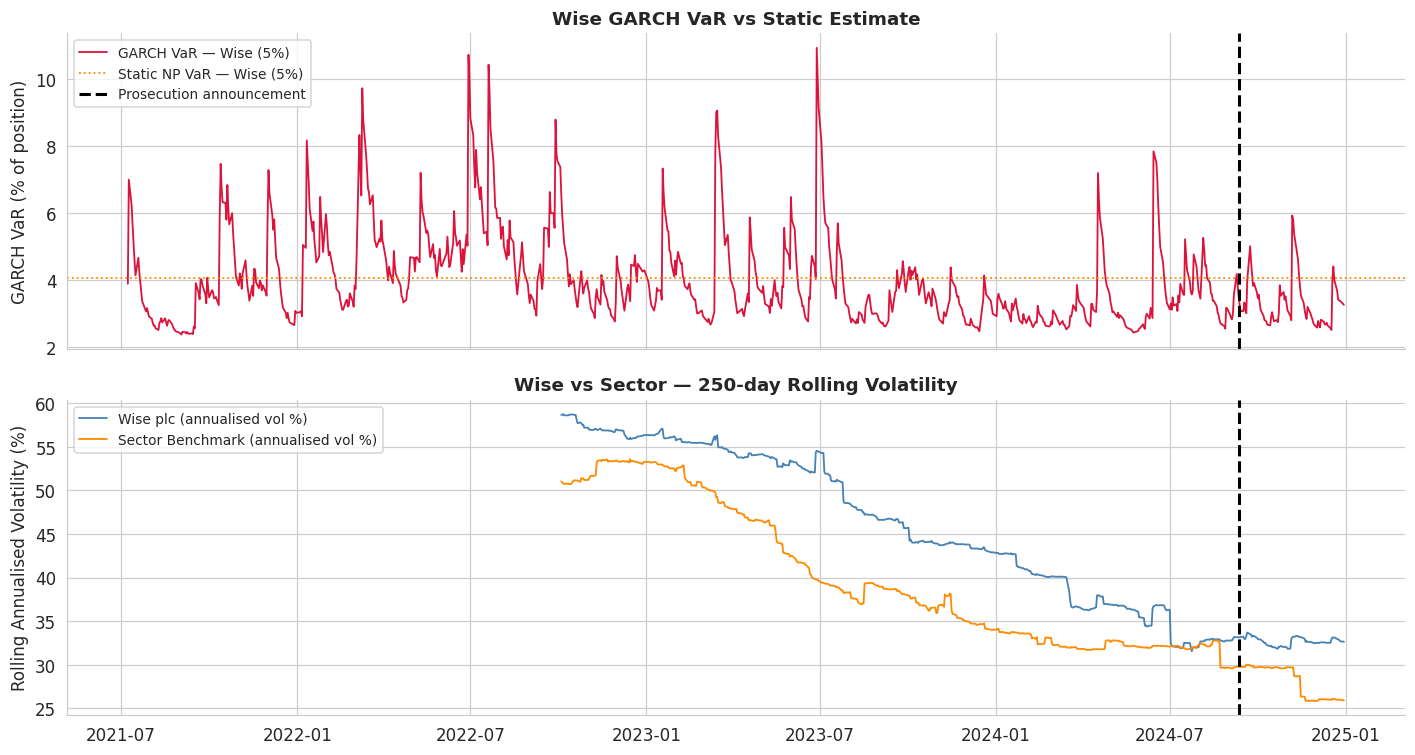

Key insight: If Wise volatility diverges from sector volatility around the event,
this confirms the risk spike is idiosyncratic (legal) rather than sector-wide.

In [19]:
# ── Figure 8: Rolling GARCH VaR — Wise vs Sector rolling std ───────────────────
# Sector rolling volatility as a simple benchmark (no full GARCH fit on sector)
roll_vol_sector = sector_a.rolling(ROLLING_WIN).std() * np.sqrt(252) * 100
roll_vol_wise   = wise_a.rolling(ROLLING_WIN).std()   * np.sqrt(252) * 100

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

axes[0].plot(garch_var.index, garch_var.values * 100,
             color=C['garch'], lw=1.2, label='GARCH VaR — Wise (5%)')
axes[0].axhline(static_var_np * 100, color=C['static'], lw=1.2, ls=':',
                label='Static NP VaR — Wise (5%)')
axes[0].axvline(pd.Timestamp(EVENT_DATE), color=C['event'], lw=2, ls='--',
                label='Prosecution announcement')
axes[0].set_ylabel('GARCH VaR (% of position)')
axes[0].set_title('Wise GARCH VaR vs Static Estimate', fontweight='bold')
axes[0].legend()

axes[1].plot(roll_vol_wise.index,   roll_vol_wise.values,
             color=C['wise'],   lw=1.2, label='Wise plc (annualised vol %)')
axes[1].plot(roll_vol_sector.index, roll_vol_sector.values,
             color=C['sector'], lw=1.2, label='Sector Benchmark (annualised vol %)')
axes[1].axvline(pd.Timestamp(EVENT_DATE), color=C['event'], lw=2, ls='--')
axes[1].set_ylabel('Rolling Annualised Volatility (%)')
axes[1].set_title(f'Wise vs Sector — {ROLLING_WIN}-day Rolling Volatility', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('09_wise_vs_sector_vol.png', bbox_inches='tight')
plt.show()

print('Key insight: If Wise volatility diverges from sector volatility around the event,')
print('this confirms the risk spike is idiosyncratic (legal) rather than sector-wide.')

---
## Summary of Findings
---

In [20]:
print('=' * 68)
print('SUMMARY OF FINDINGS — Wise plc VaR / CVaR Analysis')
print('=' * 68)

print('\n1. DISTRIBUTIONAL CHARACTERISTICS')
print(f'   Excess kurtosis : {kurt:.3f}  ({"fat-tailed" if kurt > 1 else "near-normal"})')
print(f'   Skewness        : {skew:.3f}  ({"left-skewed" if skew < 0 else "right-skewed"})')
print(f'   Normality (JB)  : {"REJECTED" if jb_p < 0.05 else "not rejected"}  (p={jb_p:.4f})')
print(f'   t-dist ν        : {nu_t:.2f} — '
      f'{"heavy fat tails" if nu_t < 5 else "moderate fat tails"} → Normal VaR understates risk')

print('\n2. VaR AND ES ESTIMATES')
print(f'   {"Method":<22} {"α=5%":>8} {"α=2.5%":>8} {"α=1%":>8}')
print('   ' + '─'*50)
for label, k1, k2 in [
    ('Nonpar VaR',  'h_var', None), ('Nonpar ES',  'h_es',  None),
    ('Normal VaR',  'n_var', None), ('Normal ES',  'n_es',  None),
    ('t-dist VaR',  't_var', None), ('t-dist ES',  't_es',  None),
]:
    vals = [res[a][k1]*100 for a in ALPHAS]
    print(f'   {label:<22} {vals[0]:>7.3f}% {vals[1]:>7.3f}% {vals[2]:>7.3f}%')

print('\n3. KUPIEC BACKTESTING')
for a in ALPHAS:
    k = kup[a]
    print(f'   α={a:.1%}: obs={k["p_hat"]:.4f}, exp={a:.4f}, '
          f'p={k["pval"]:.4f} → {"PASS" if k["passed"] else "FAIL"}')

print('\n4. SECTOR COMPARISON (α=5%)')
print(f'   Wise VaR:              {w_var*100:.3f}%')
print(f'   Sector VaR:            {s_var*100:.3f}%')
print(f'   Idiosyncratic premium: {(w_var-s_var)*100:+.3f}%')

print('\n5. BOOTSTRAP PRECISION (α=5%)')
r5 = boot[0.05]
print(f'   VaR  95% CI: [{r5["var_ci"][0]*100:.3f}%, {r5["var_ci"][1]*100:.3f}%]')
print(f'   ES   95% CI: [{r5["es_ci"][0]*100:.3f}%, {r5["es_ci"][1]*100:.3f}%]')

print('\n' + '=' * 68)
print('Figures saved: 01_eda · 02_loss_dist · 03_param_fits · 04_bootstrap')
print('               05_breaches · 06_garch · 07_event · 08_sector · 09_vol')
print('=' * 68)

SUMMARY OF FINDINGS — Wise plc VaR / CVaR Analysis

1. DISTRIBUTIONAL CHARACTERISTICS
   Excess kurtosis : 5.220  (fat-tailed)
   Skewness        : 0.020  (right-skewed)
   Normality (JB)  : REJECTED  (p=0.0000)
   t-dist ν        : 3.02 — heavy fat tails → Normal VaR understates risk

2. VaR AND ES ESTIMATES
   Method                     α=5%   α=2.5%     α=1%
   ──────────────────────────────────────────────────
   Nonpar VaR               4.078%   5.203%   8.065%
   Nonpar ES                6.503%   8.442%  10.857%
   Normal VaR               4.532%   5.412%   6.434%
   Normal ES                5.698%   6.466%   7.380%
   t-dist VaR               4.065%   5.525%   7.911%
   t-dist ES                6.737%   8.782%  12.223%

3. KUPIEC BACKTESTING
   α=5.0%: obs=0.0207, exp=0.0500, p=0.0001 → FAIL
   α=2.5%: obs=0.0112, exp=0.0250, p=0.0129 → FAIL
   α=1.0%: obs=0.0064, exp=0.0100, p=0.3291 → PASS

4. SECTOR COMPARISON (α=5%)
   Wise VaR:              4.160%
   Sector VaR:            